In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Load Diabetes Dataset
diabetes = load_diabetes()

X = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

y = diabetes.target

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 rows:")
display(X.head())


Dataset loaded successfully!
Features shape: (442, 10)
Target shape: (442,)

First 5 rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [3]:
# Split dataset into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training and Testing split completed!")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Training and Testing split completed!
X_train shape: (353, 10)
X_test shape: (89, 10)
y_train shape: (353,)
y_test shape: (89,)


In [4]:
# Create Linear Regression Model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict test data
y_pred = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

print("First 5 Actual Values:", y_test[:5].values)
print("First 5 Predicted Values:", y_pred[:5])


Linear Regression model trained successfully!


AttributeError: 'numpy.ndarray' object has no attribute 'values'

In [5]:
# Calculate Regression Metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("========== LINEAR REGRESSION METRICS ==========")

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R-squared: {r2:.2f}")


========== LINEAR REGRESSION METRICS ==========
MAE: 42.79
RMSE: 53.85
R-squared: 0.45


In [6]:
# Calculate mean of training target
baseline_prediction = np.mean(y_train)

# Predict all test samples using training mean
baseline_pred = np.full(len(y_test), baseline_prediction)

# Calculate Baseline Metrics
baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

print("========== BASELINE MODEL METRICS ==========")

print(f"Training Target Mean: {baseline_prediction:.2f}")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")


========== BASELINE MODEL METRICS ==========
Training Target Mean: 153.74
Baseline MAE: 64.01
Baseline RMSE: 73.22


In [14]:
baseline_r2 = r2_score(y_test, baseline_pred)

comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2": [baseline_r2, r2]
})

display(comparison.round(2))

,Model,MAE,RMSE,R2
0,Baseline,64.01,73.22,-0.01
1,Linear Regression,42.79,53.85,0.45


Model Usefulness

1. Linear Regression performs better than the baseline if it has lower MAE and RMSE.
2. The model captures some patterns in the diabetes dataset, but its R-squared value shows that prediction performance is moderate.
3. Therefore, the model is useful for estimating trends but should not be treated as a highly accurate prediction system.

Metrics for Non-Technical Clients

1. I would show MAE because it explains the average prediction error in simple numerical terms.
2. It is easy for non-technical clients to understand how far predictions are from actual values on average.

In [8]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

In [9]:
# Load Iris dataset
iris = load_iris()

X_iris = iris.data

# Setosa = 1, Other species = 0
y_iris = (iris.target == 0).astype(int)

print("Iris dataset loaded successfully!")
print("Setosa samples:", sum(y_iris))
print("Other species:", len(y_iris) - sum(y_iris))

Iris dataset loaded successfully!
Setosa samples: 50
Other species: 100


In [10]:
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

print("Iris train-test split completed!")
print("Training samples:", len(X_train_iris))
print("Testing samples:", len(X_test_iris))

Iris train-test split completed!
Training samples: 120
Testing samples: 30


In [11]:
# Train binary classification model
iris_model = LogisticRegression(max_iter=200)

iris_model.fit(X_train_iris, y_train_iris)

# Predict probabilities
y_prob = iris_model.predict_proba(X_test_iris)[:, 1]

print("Binary classification model trained successfully!")

Binary classification model trained successfully!


In [12]:
# Calculate AUC
auc_score = roc_auc_score(y_test_iris, y_prob)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test_iris, y_prob)

print(f"AUC Score: {auc_score:.2f}")

AUC Score: 1.00


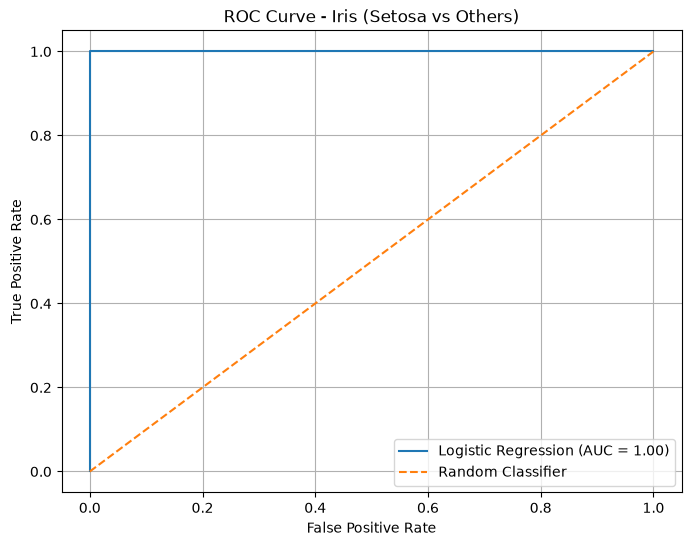

In [13]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.2f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Iris (Setosa vs Others)")

plt.legend()
plt.grid()

plt.show()